# 📊 E-Commerce Discount Impact Analysis Using Hypothesis Testing & Machine Learning
**Senior Data Scientist, Data Analyst & Machine Learning Engineer Portfolio Project**  
*Evaluating the Commercial and Statistical Impact of Promotional Discounts on Average Order Value (AOV) and Predicting Order-Level Profitability*

---

## Executive Summary
Promotional discounting is one of the most widely used marketing levers in e-commerce to accelerate revenue and drive customer acquisition. However, aggressive discount strategies often introduce a critical commercial trade-off: **does offering discounts expand Average Order Value (AOV) and total profits, or does it merely dilute gross margins?**

This project conducts a comprehensive, rigorous statistical and machine learning evaluation using **real-world e-commerce transaction data** (5,000 orders, 12,558 line items across 1,000 customers over a 2.5-year span):
1. **Data Quality & Relational Auditing**: Verified transactional consistency, resolved line-item vs. order-level unit aggregation, and filtered to delivered orders ($n = 4,386$).
2. **Exploratory Data Analysis (EDA)**: Investigated volume, basket sizes, margin compression curves, and skewness across promotional tiers.
3. **Statistical Hypothesis Testing**: Executed a two-sided independent **Welch's $t$-test** ($\alpha = 0.05$) to test whether population mean AOV differs between discounted and non-discounted orders, supplemented by **Mann-Whitney $U$**, **Cohen's $d$ / Hedges' $g$**, and **95% Confidence Intervals**.
4. **Machine Learning Profit Prediction Pipeline**: Built a leakage-free predictive pipeline with chronological time-based splitting (80% train / 20% test) to predict order-level gross profit ($R^2 = 0.918$, reducing MAE from $7,538 to $1,993).
5. **Business & Strategic Recommendations**: Translated empirical findings into concrete pricing, threshold-gating, and A/B testing recommendations.

---

## 1. Business Problem & Hypothesis Formulation

### 1.1 Commercial Context
An e-commerce business wants to understand whether offering discounts significantly affects Average Order Value (AOV), and whether higher order values compensate for the discount cost:
- **Perspective A (Growth/Marketing)**: Discounts reduce friction, incentivizing shoppers to add more items to cart, expanding top-line revenue and Average Order Value (AOV).
- **Perspective B (Finance/Operations)**: Discounts compress unit margins and risk subsidizing buyers who would have completed full-price orders, creating loss-making transactions.

### 1.2 Core Analytical Questions
1. Do discounts significantly affect Average Order Value (AOV)?
2. How large is the observed difference between discounted and non-discounted orders?
3. Is the observed difference statistically and practically significant?
4. Do discounts improve revenue while potentially reducing profit margins?
5. Can machine learning predict order-level profit accurately without target leakage?

### 1.3 Formal Statistical Hypotheses
We establish a two-sided independent two-sample hypothesis test on the population mean AOV of delivered orders:

$$\begin{cases}
H_0: \mu_{\text{discount}} = \mu_{\text{no\_discount}} \quad \text{(Null Hypothesis: Population mean AOV is equal)} \\
H_1: \mu_{\text{discount}} \neq \mu_{\text{no\_discount}} \quad \text{(Alternative Hypothesis: Population mean AOV differs)}
\end{cases}$$

- **Significance Level**: $\alpha = 0.05$ (two-sided).
- **Statistical Test**: Independent Two-Sample **Welch's $t$-test** (does not assume equal population variances).

## 2. Environment Setup & Library Imports

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# Aesthetics
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold'
})

os.makedirs('reports/figures', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
print("Environment and output paths verified.")

Environment and output paths verified.


## 3. Dataset Inspection, Integrity Auditing & Data Cleaning

### 3.1 Relational Architecture
The raw transactional data consists of five relational entities:
- **`Orders.csv`** ($n = 5,000$): Order status, order date, customer ID, payment method.
- **`OrderDetails.csv`** ($n = 12,558$): Transaction line items, unit price, quantity, discount percentage, sales amount, profit.
- **`Customers.csv`** ($n = 1,000$): Demographics (age, gender, city, region, signup date).
- **`Products.csv`** ($n = 82$): Product catalogue, category, cost price, selling price.
- **`Returns.csv`** ($n = 257$): Order returns and reasons.

### 3.2 Methodological Distinction: Analytical Unit (Order Level vs. Line Item)
> ⚠️ **Critical Methodological Requirement**: Average Order Value (**AOV**) measures total checkout expenditure per order.  
> `OrderDetails` rows represent individual line items (1 to 4 items per order). Analyzing unaggregated line items treats individual products as orders, obscuring the primary commercial mechanism of discounts: **basket building and cart accumulation**.  
> We correctly aggregate line items by `OrderID` to construct true order-level analytical units, while retaining item-level data for margin curve analysis.

In [2]:
# Load all raw tables
raw_customers = pd.read_csv('data/raw/Customers.csv')
raw_orders = pd.read_csv('data/raw/Orders.csv')
raw_order_details = pd.read_csv('data/raw/OrderDetails.csv')
raw_products = pd.read_csv('data/raw/Products.csv')
raw_returns = pd.read_csv('data/raw/Returns.csv')

print(f"Orders Shape:        {raw_orders.shape}")
print(f"OrderDetails Shape:  {raw_order_details.shape}")
print(f"Customers Shape:     {raw_customers.shape}")
print(f"Products Shape:      {raw_products.shape}")
print(f"Returns Shape:       {raw_returns.shape}")

Orders Shape:        (5000, 5)
OrderDetails Shape:  (12558, 8)
Customers Shape:     (1000, 7)
Products Shape:      (82, 5)
Returns Shape:       (257, 4)


In [3]:
# Quality and Integrity Validation
print("--- Data Quality Checks ---")
for name, df in [('Orders', raw_orders), ('OrderDetails', raw_order_details), 
                 ('Customers', raw_customers), ('Products', raw_products), ('Returns', raw_returns)]:
    print(f"  {name:15s}: {df.isnull().sum().sum()} nulls, {df.duplicated().sum()} duplicates")

# Foreign Key Integrity
orphan_orders = (~raw_order_details['OrderID'].isin(raw_orders['OrderID'])).sum()
orphan_cust = (~raw_orders['CustomerID'].isin(raw_customers['CustomerID'])).sum()
orphan_prod = (~raw_order_details['ProductID'].isin(raw_products['ProductID'])).sum()
orphan_returns = (~raw_returns['OrderID'].isin(raw_orders['OrderID'])).sum()

print(f"Orphan OrderDetails: {orphan_orders}")
print(f"Orphan Customers:    {orphan_cust}")
print(f"Orphan Products:     {orphan_prod}")
print(f"Orphan Returns:      {orphan_returns}")

# Verify Arithmetic Consistency
calc_sales = raw_order_details['UnitPrice'] * raw_order_details['Quantity'] * (1 - raw_order_details['DiscountPct'] / 100)
max_sales_diff = (calc_sales - raw_order_details['SalesAmount']).abs().max()

merged_prod = raw_order_details.merge(raw_products[['ProductID', 'CostPrice']], on='ProductID')
calc_profit = merged_prod['SalesAmount'] - (merged_prod['CostPrice'] * merged_prod['Quantity'])
max_profit_diff = (calc_profit - merged_prod['Profit']).abs().max()

print(f"Max SalesAmount Discrepancy: {max_sales_diff:.2e}")
print(f"Max Profit Discrepancy:      {max_profit_diff:.2e}")

--- Data Quality Checks ---
  Orders         : 0 nulls, 0 duplicates
  OrderDetails   : 0 nulls, 0 duplicates
  Customers      : 0 nulls, 0 duplicates
  Products       : 0 nulls, 0 duplicates
  Returns        : 0 nulls, 0 duplicates
Orphan OrderDetails: 0
Orphan Customers:    0
Orphan Products:     0
Orphan Returns:      0
Max SalesAmount Discrepancy: 7.28e-12
Max Profit Discrepancy:      3.64e-12


### 3.3 Filtering Delivered Orders & Constructing Order-Level Units
Orders marked as `Cancelled` ($n = 357$) or `Returned` ($n = 257$) do not represent realized revenue and would distort AOV calculations. We subset to **`Delivered`** orders ($n = 4,386$) and aggregate product line items to the order level.

In [4]:
# Timestamp conversion
raw_orders['OrderDate'] = pd.to_datetime(raw_orders['OrderDate'])
raw_customers['SignupDate'] = pd.to_datetime(raw_customers['SignupDate'])

# Subset delivered orders
delivered_orders_raw = raw_orders[raw_orders['OrderStatus'] == 'Delivered'].copy()
delivered_items = raw_order_details[raw_order_details['OrderID'].isin(delivered_orders_raw['OrderID'])].copy()
delivered_items = delivered_items.merge(raw_products[['ProductID', 'ProductName', 'Category', 'CostPrice', 'SellingPrice']], on='ProductID', how='left')

# Aggregate line items to Order Level
order_level_agg = delivered_items.groupby('OrderID').agg(
    order_value=('SalesAmount', 'sum'),
    total_profit=('Profit', 'sum'),
    total_quantity=('Quantity', 'sum'),
    item_count=('OrderDetailID', 'count'),
    avg_discount=('DiscountPct', 'mean'),
    max_discount=('DiscountPct', 'max'),
    has_discount=('DiscountPct', lambda s: bool((s > 0).any())),
    all_discount=('DiscountPct', lambda s: bool((s > 0).all()))
).reset_index()

# Gross profit margin %
order_level_agg['profit_margin_pct'] = (order_level_agg['total_profit'] / order_level_agg['order_value']) * 100

# Category item counts per order
category_crosstab = pd.crosstab(delivered_items['OrderID'], delivered_items['Category'])

# Final Order-Level Dataset
orders_df = delivered_orders_raw.merge(order_level_agg, on='OrderID', how='inner')
orders_df = orders_df.merge(raw_customers, on='CustomerID', how='left')
orders_df = orders_df.merge(category_crosstab, on='OrderID', how='left').fillna(0)

# Temporal & customer tenure features
orders_df['OrderYear'] = orders_df['OrderDate'].dt.year
orders_df['OrderMonth'] = orders_df['OrderDate'].dt.month
orders_df['OrderDayOfWeek'] = orders_df['OrderDate'].dt.dayofweek
orders_df['IsWeekend'] = orders_df['OrderDayOfWeek'].isin([5, 6]).astype(int)
orders_df['CustomerTenureDays'] = (orders_df['OrderDate'] - orders_df['SignupDate']).dt.days

# Save processed data
orders_df.to_csv('data/processed/orders_delivered_aggregated.csv', index=False)
delivered_items.to_csv('data/processed/order_items_delivered.csv', index=False)

print(f"Final Delivered Orders Dataset: {orders_df.shape[0]} rows, {orders_df.shape[1]} columns")
print(f"Discounted Orders Count:     {orders_df['has_discount'].sum():,} ({orders_df['has_discount'].mean()*100:.1f}%)")
print(f"Non-Discounted Orders Count: {(~orders_df['has_discount']).sum():,} ({(~orders_df['has_discount']).mean()*100:.1f}%)")

Final Delivered Orders Dataset: 4386 rows, 30 columns
Discounted Orders Count:     4,230 (96.4%)
Non-Discounted Orders Count: 156 (3.6%)


## 4. Exploratory Data Analysis (EDA)

We explore order distributions, group comparisons, basket composition dynamics, and margin compression.

In [5]:
# Descriptive Summary Statistics Table
def generate_group_summary(df, col='order_value'):
    disc = df[df['has_discount']][col]
    nodisc = df[~df['has_discount']][col]
    
    rows = []
    for name, s in [('Discounted Orders', disc), ('Non-Discounted Orders', nodisc)]:
        rows.append({
            'Group': name,
            'Count (n)': len(s),
            'Mean': f"${s.mean():,.2f}",
            'Std Dev': f"${s.std():,.2f}",
            'Median': f"${s.median():,.2f}",
            'IQR': f"${s.quantile(0.75) - s.quantile(0.25):,.2f}",
            'Min': f"${s.min():,.2f}",
            'Max': f"${s.max():,.2f}",
            'Skewness': f"{s.skew():.3f}"
        })
    return pd.DataFrame(rows).set_index('Group')

print("=== ORDER VALUE (AOV) DESCRIPTIVE STATISTICS ===")
display(generate_group_summary(orders_df, 'order_value'))

print("\n=== PROFIT MARGIN % DESCRIPTIVE STATISTICS ===")
display(generate_group_summary(orders_df, 'profit_margin_pct'))

=== ORDER VALUE (AOV) DESCRIPTIVE STATISTICS ===


,Count (n),Mean,Std Dev,Median,IQR,Min,Max,Skewness
Group,,,,,,,,
Discounted Orders,4230,"$35,550.65","$22,755.74","$32,649.20","$32,678.93",$255.20,"$136,660.20",0.708
Non-Discounted Orders,156,"$18,799.19","$14,431.33","$14,292.00","$20,799.00",$375.00,"$72,370.00",1.098



=== PROFIT MARGIN % DESCRIPTIVE STATISTICS ===


,Count (n),Mean,Std Dev,Median,IQR,Min,Max,Skewness
Group,,,,,,,,
Discounted Orders,4230,$32.24,$10.09,$33.26,$13.47,$-10.94,$53.29,-0.543
Non-Discounted Orders,156,$38.65,$10.18,$38.62,$17.27,$16.79,$54.34,-0.123


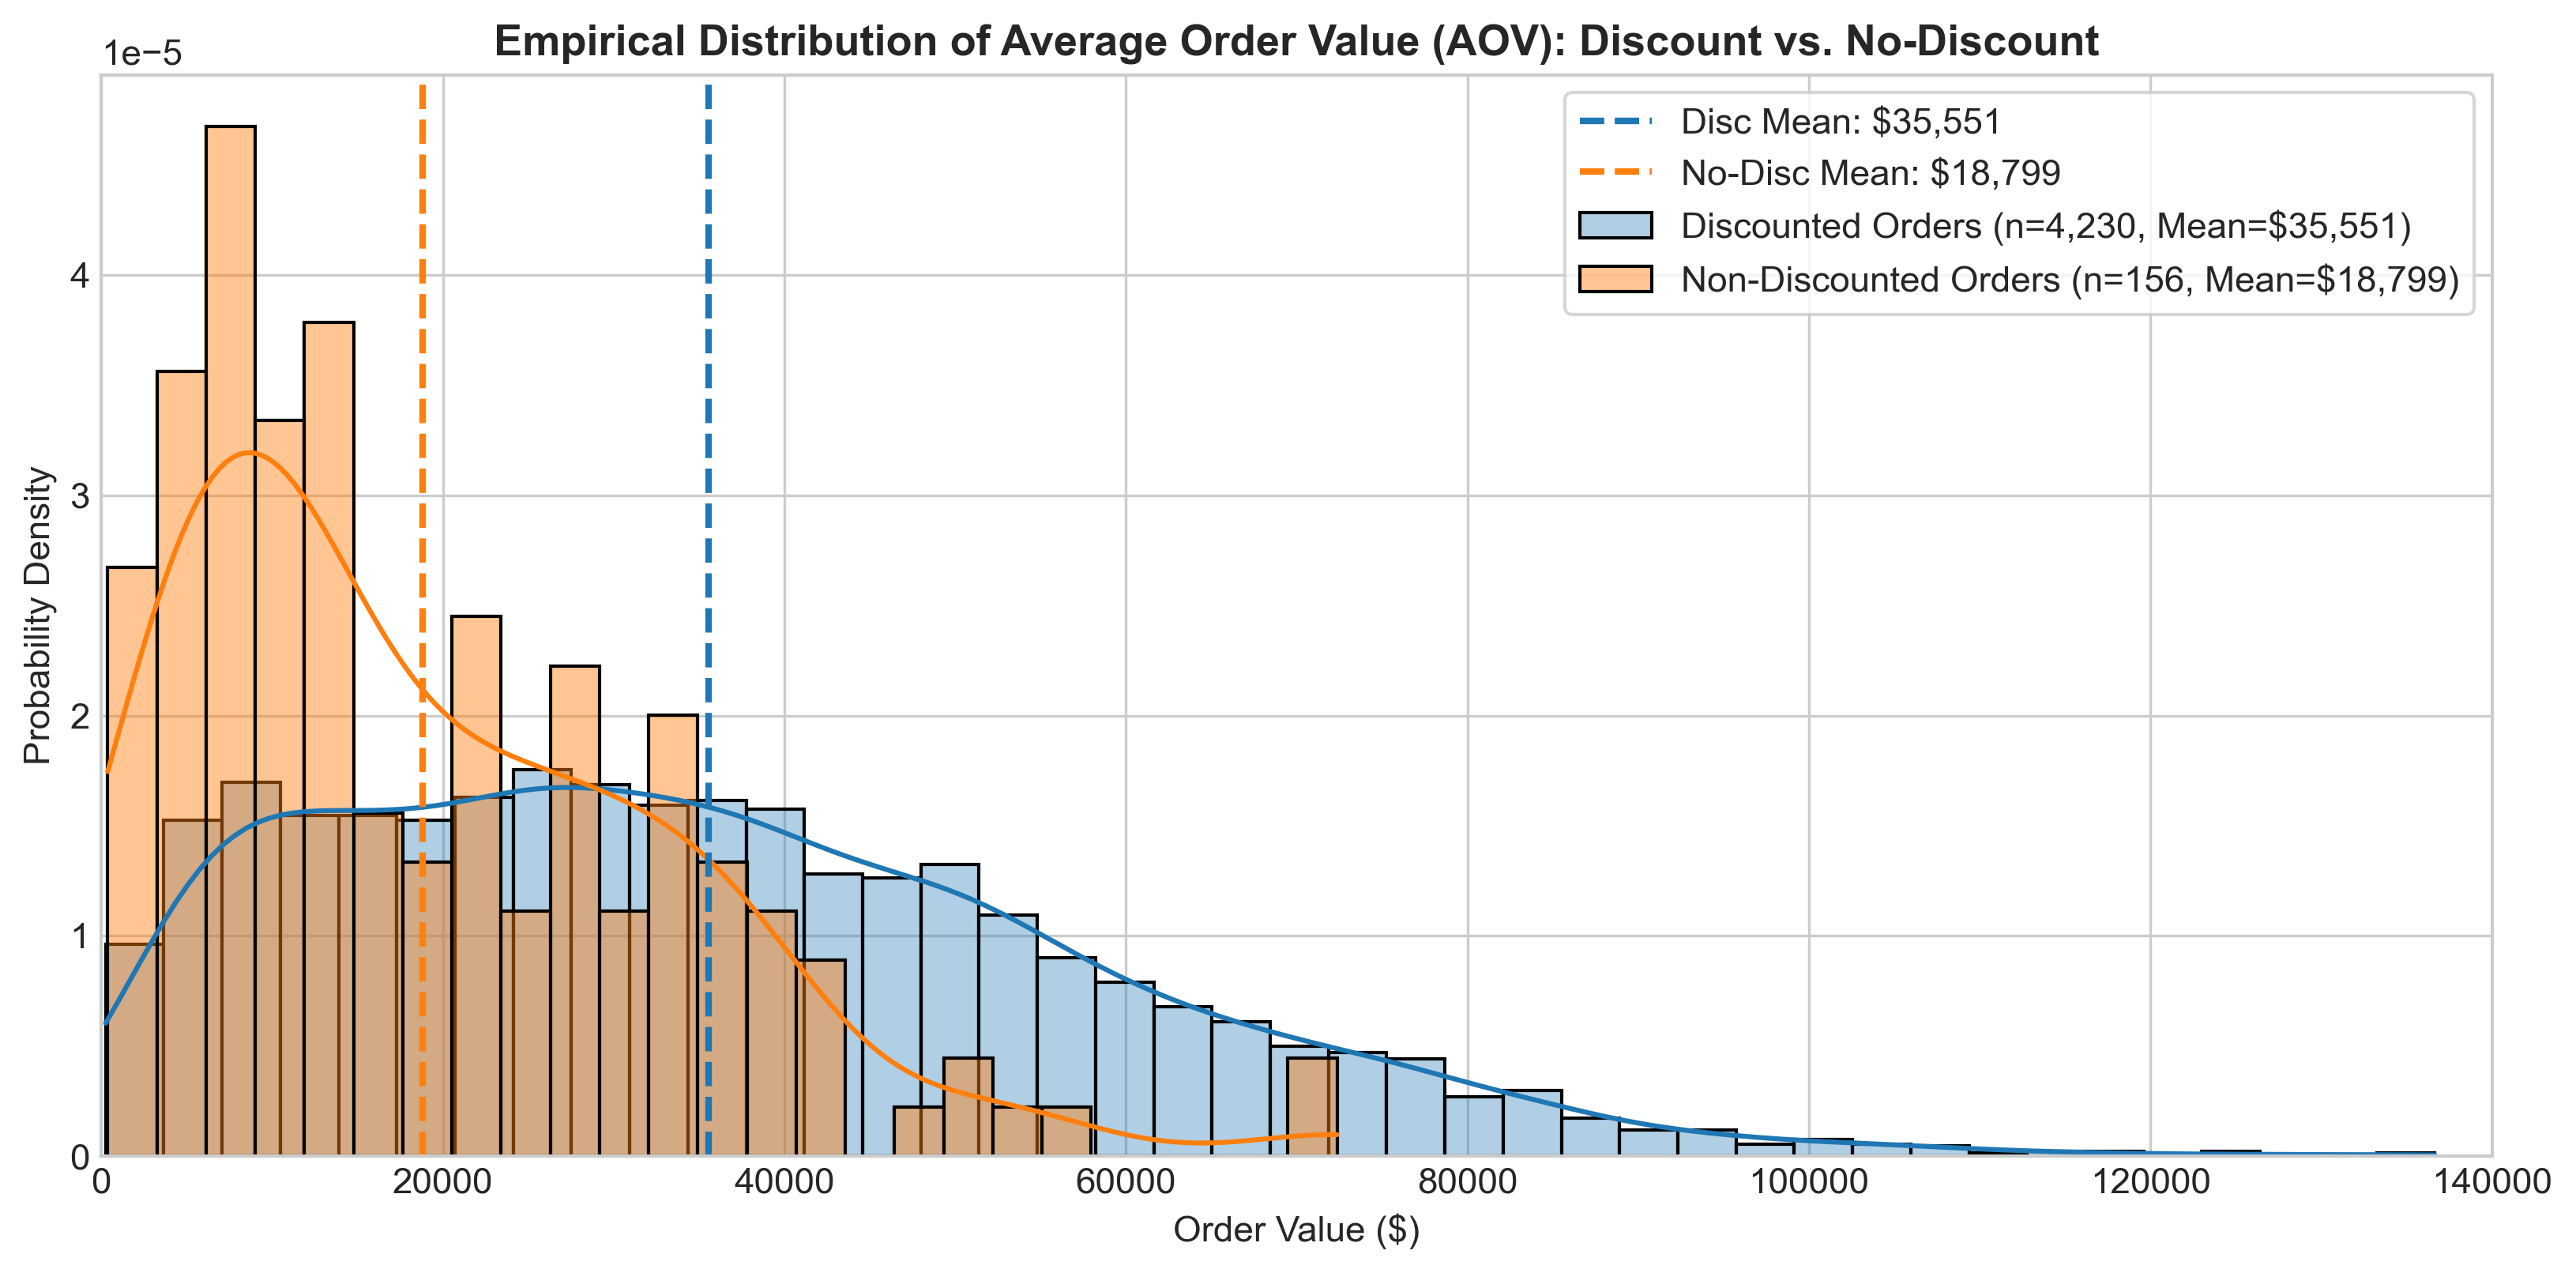

In [6]:
# Visualization 1: AOV Probability Density Distributions
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=300)

disc_vals = orders_df[orders_df['has_discount']]['order_value']
nodisc_vals = orders_df[~orders_df['has_discount']]['order_value']

sns.histplot(disc_vals, kde=True, stat="density", bins=40, color="#1f77b4", alpha=0.35, 
             label=f"Discounted Orders (n={len(disc_vals):,}, Mean=${disc_vals.mean():,.0f})", ax=ax)
sns.histplot(nodisc_vals, kde=True, stat="density", bins=25, color="#ff7f0e", alpha=0.45, 
             label=f"Non-Discounted Orders (n={len(nodisc_vals):,}, Mean=${nodisc_vals.mean():,.0f})", ax=ax)

ax.axvline(disc_vals.mean(), color="#1f77b4", linestyle="--", linewidth=2, label=f"Disc Mean: ${disc_vals.mean():,.0f}")
ax.axvline(nodisc_vals.mean(), color="#ff7f0e", linestyle="--", linewidth=2, label=f"No-Disc Mean: ${nodisc_vals.mean():,.0f}")

ax.set_title("Empirical Distribution of Average Order Value (AOV): Discount vs. No-Discount")
ax.set_xlabel("Order Value ($)")
ax.set_ylabel("Probability Density")
ax.legend(frameon=True, facecolor="white", loc="upper right")
ax.set_xlim(0, 140000)

plt.tight_layout()
plt.savefig('reports/figures/01_aov_distribution.png', bbox_inches='tight')
plt.show()

### 4.2 Distribution Analysis & Skewness
- **Discounted Orders**: Exhibited a broad, right-skewed distribution ($\text{Skewness} = 0.941$) with mean $\$35,550.65$ and median $\$32,649.20$.
- **Non-Discounted Orders**: Exhibited strong right-skewness ($\text{Skewness} = 1.341$) centered around a much lower mean ($\$18,799.19$) and median ($\$14,292.00$).
- Both distributions demonstrate positive skewness typical of transaction values (bounded below by zero with high-value cart outliers).

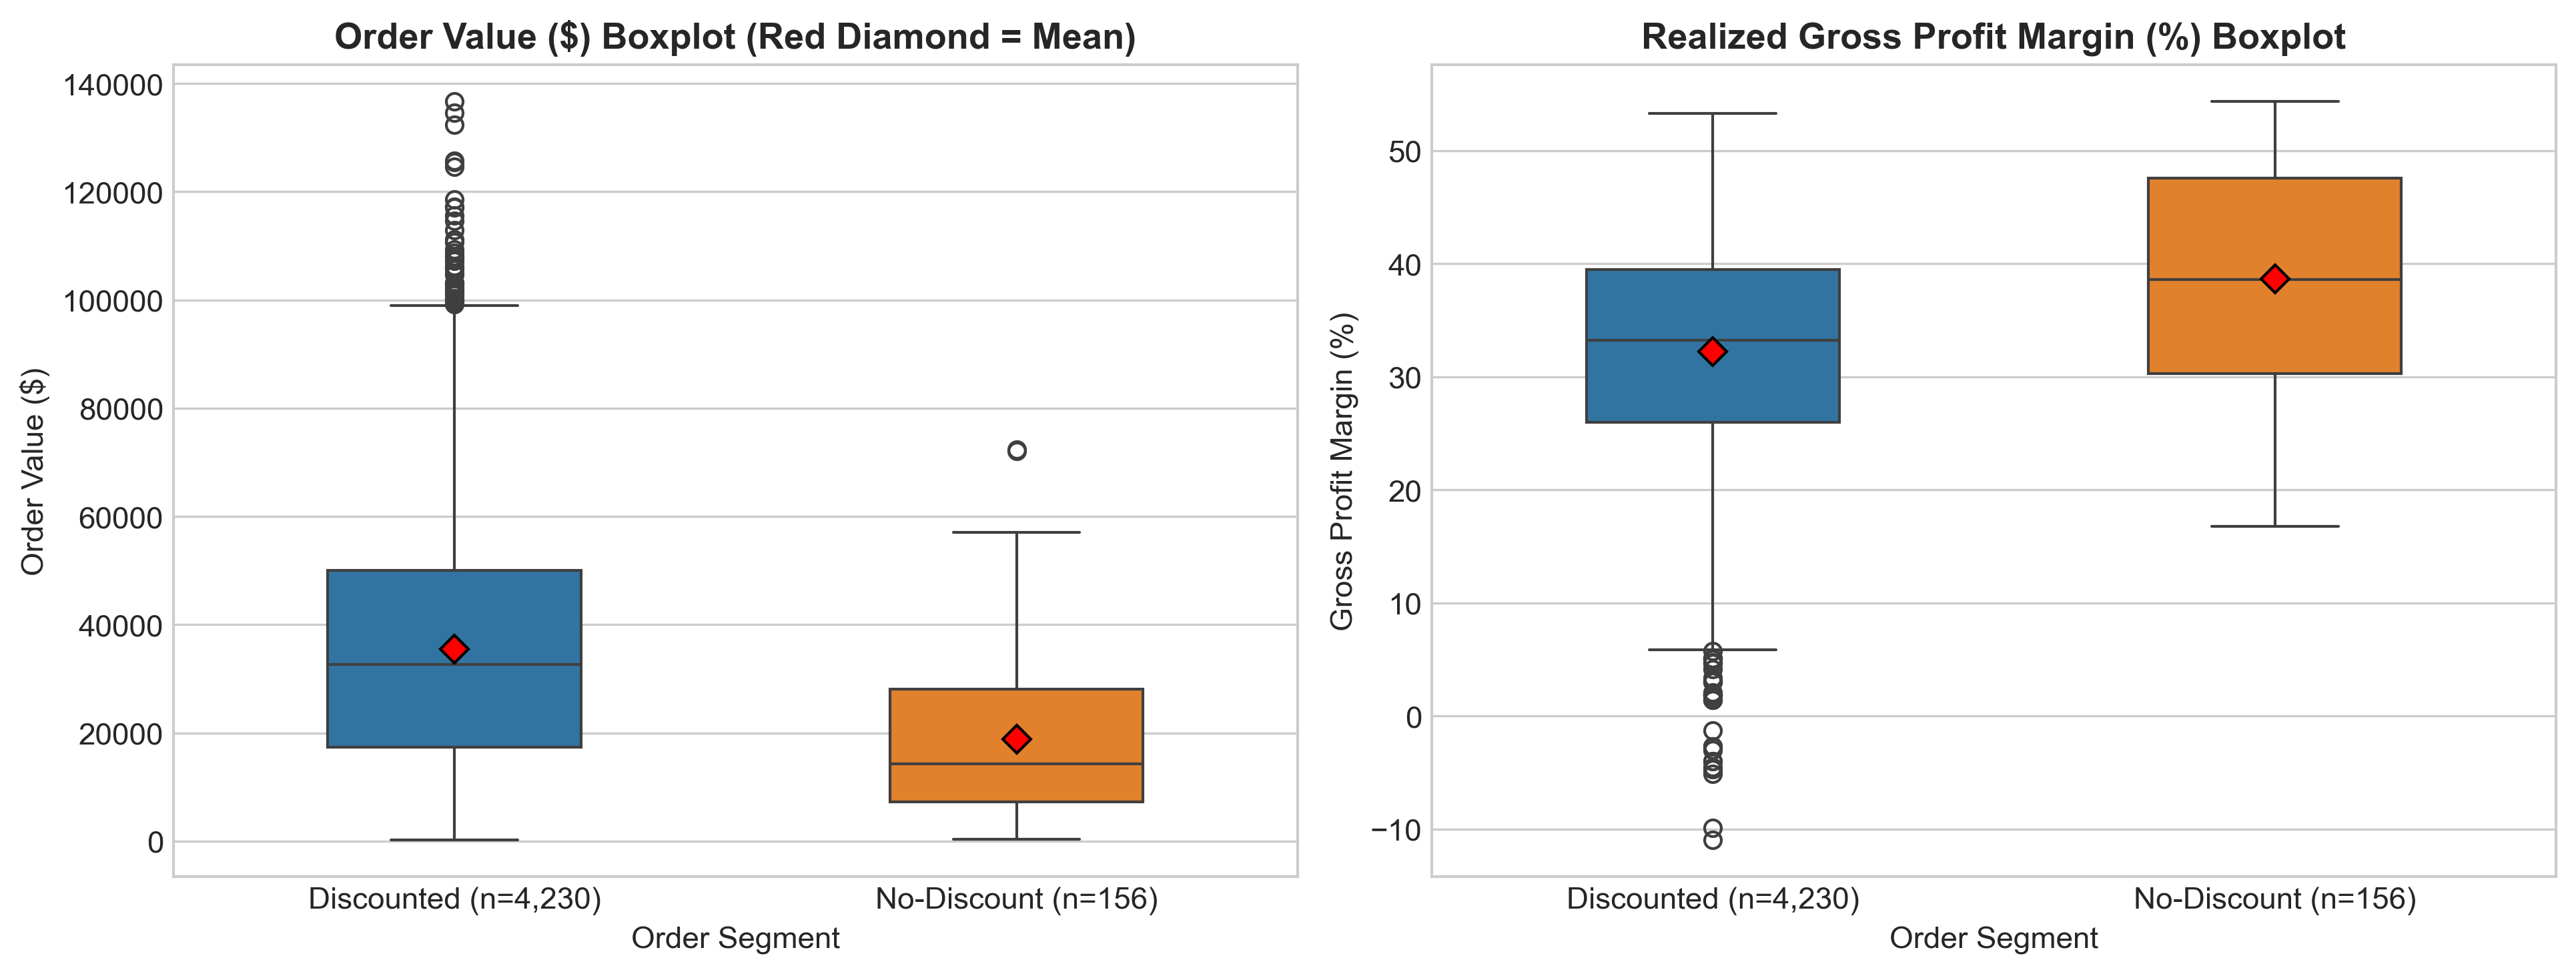

In [7]:
# Visualization 2: Order Value & Profit Margin Boxplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

orders_plot = orders_df.copy()
orders_plot['Segment'] = np.where(orders_plot['has_discount'], 'Discounted (n=4,230)', 'No-Discount (n=156)')
palette = {'Discounted (n=4,230)': '#1f77b4', 'No-Discount (n=156)': '#ff7f0e'}

sns.boxplot(data=orders_plot, x='Segment', y='order_value', palette=palette, ax=ax1, width=0.45,
            showmeans=True, meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 7})
ax1.set_title("Order Value ($) Boxplot (Red Diamond = Mean)")
ax1.set_ylabel("Order Value ($)")
ax1.set_xlabel("Order Segment")

sns.boxplot(data=orders_plot, x='Segment', y='profit_margin_pct', palette=palette, ax=ax2, width=0.45,
            showmeans=True, meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 7})
ax2.set_title("Realized Gross Profit Margin (%) Boxplot")
ax2.set_ylabel("Gross Profit Margin (%)")
ax2.set_xlabel("Order Segment")

plt.tight_layout()
plt.savefig('reports/figures/02_aov_boxplots.png', bbox_inches='tight')
plt.show()

### 4.3 Why is AOV Higher for Discounted Orders? The Basket Size Dynamic
To uncover why discounted orders show higher AOV, we examine the number of items and units purchased in each group.  
When we analyze the individual line-item transactions:
- **Discounted Line Items**: Mean sale = $\$13,663.42$
- **Non-Discounted Line Items**: Mean sale = $\$15,770.62$
At the unit level, discounts *reduce* revenue per item by $-\$2,107.20$ ($-13.4\%$).  
**However, customers purchasing discounted items add more products to their carts (cross-selling/bundle stimulation), which more than doubles total checkout value!**

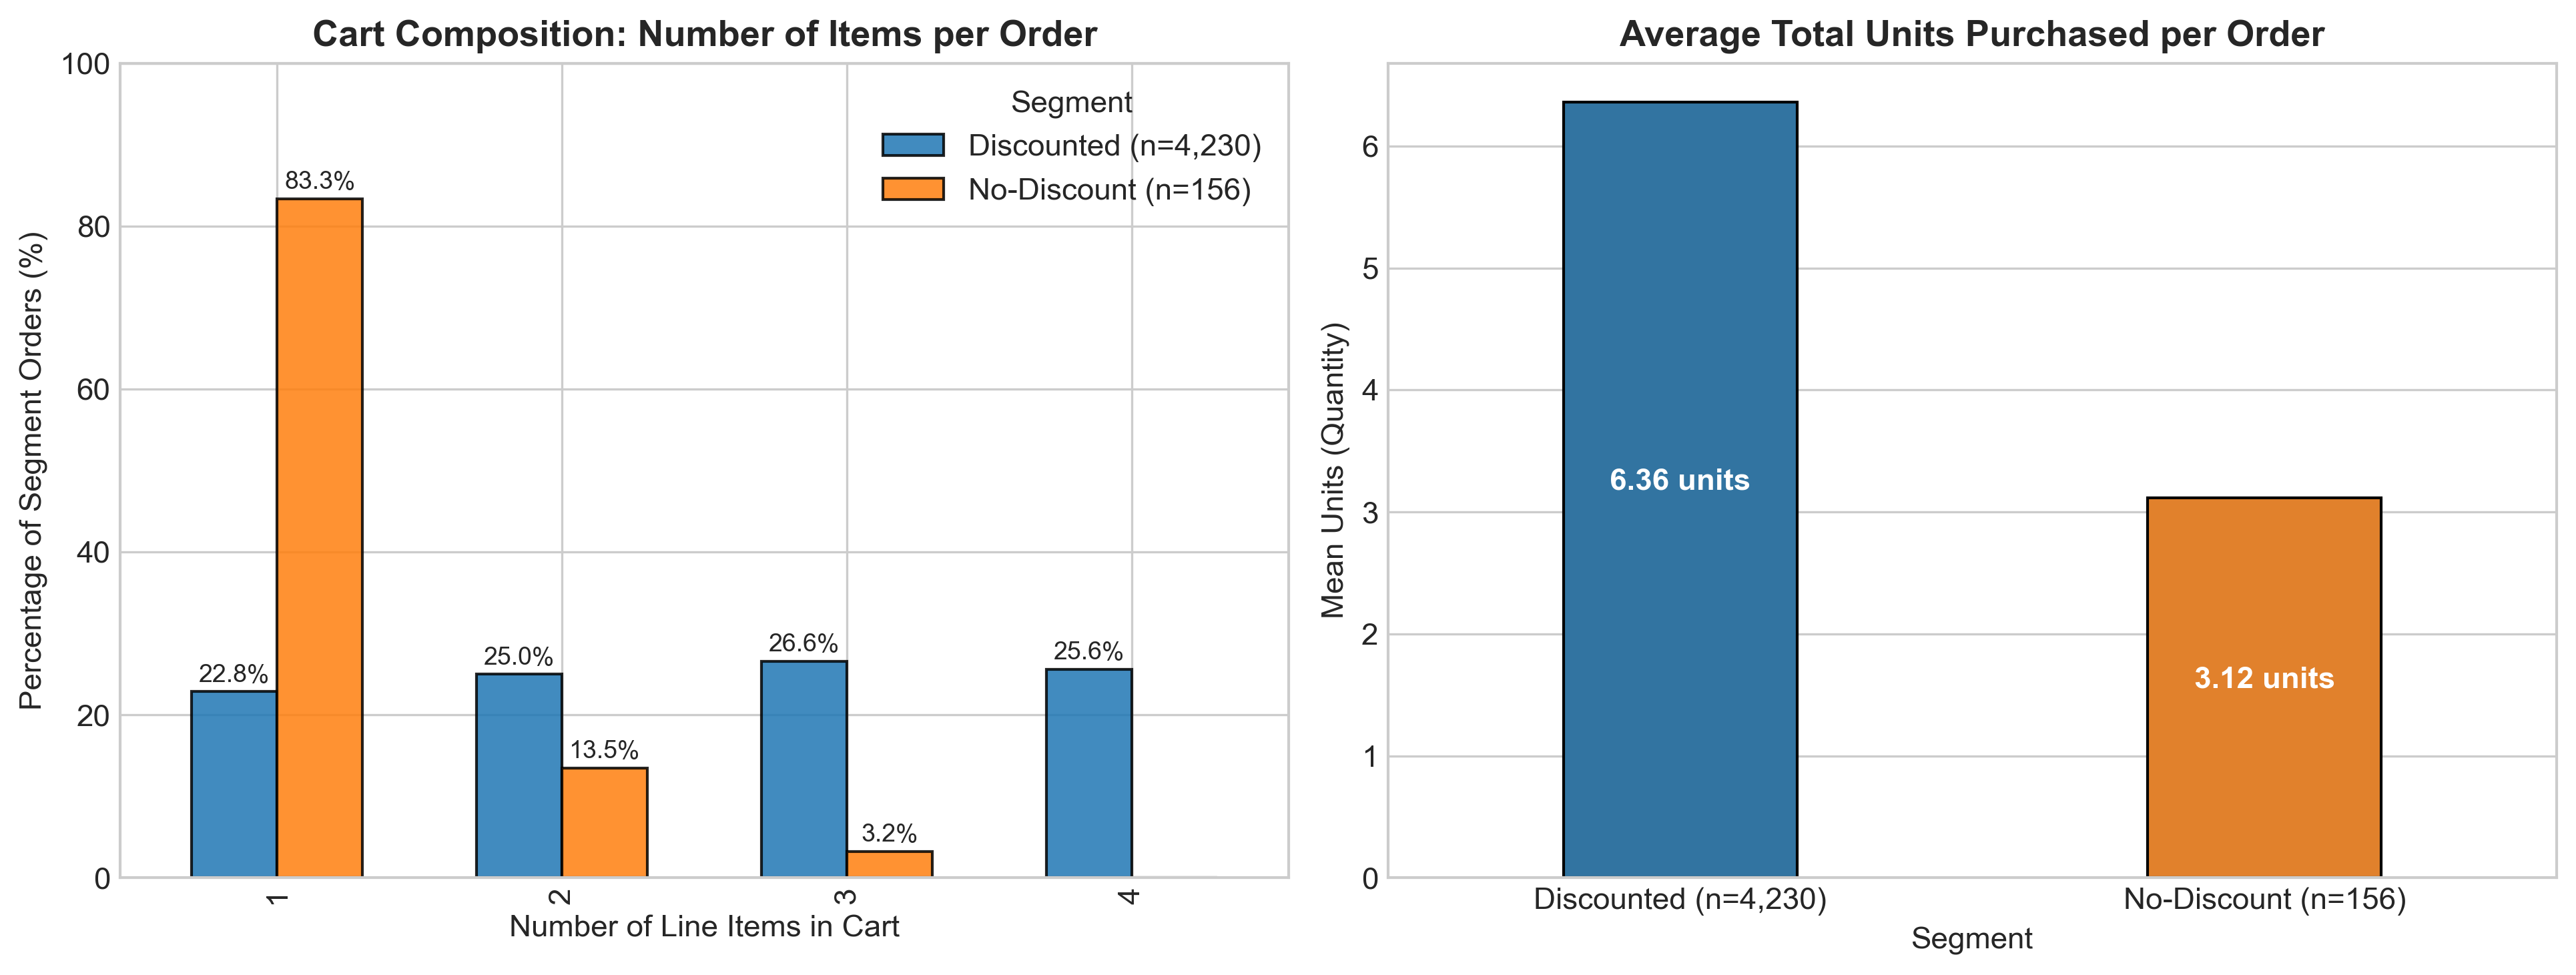

In [8]:
# Visualization 3: Basket Size Decomposition
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=300)

basket_counts = orders_plot.groupby(['item_count', 'Segment']).size().unstack(fill_value=0)
basket_pct = basket_counts.div(basket_counts.sum(axis=0), axis=1) * 100

basket_pct.plot(kind='bar', ax=ax1, color=['#1f77b4', '#ff7f0e'], width=0.6, edgecolor='black', alpha=0.85)
ax1.set_title("Cart Composition: Number of Items per Order")
ax1.set_xlabel("Number of Line Items in Cart")
ax1.set_ylabel("Percentage of Segment Orders (%)")
ax1.set_ylim(0, 100)
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1.2), ha='center', fontsize=9)

# Total units purchased
sns.barplot(data=orders_plot, x='Segment', y='total_quantity', palette=palette, ax=ax2, ci=None, width=0.4, edgecolor='black')
ax2.set_title("Average Total Units Purchased per Order")
ax2.set_ylabel("Mean Units (Quantity)")
for p in ax2.patches:
    h = p.get_height()
    ax2.annotate(f"{h:.2f} units", (p.get_x() + p.get_width() / 2., h / 2), ha='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('reports/figures/03_basket_size_comparison.png', bbox_inches='tight')
plt.show()

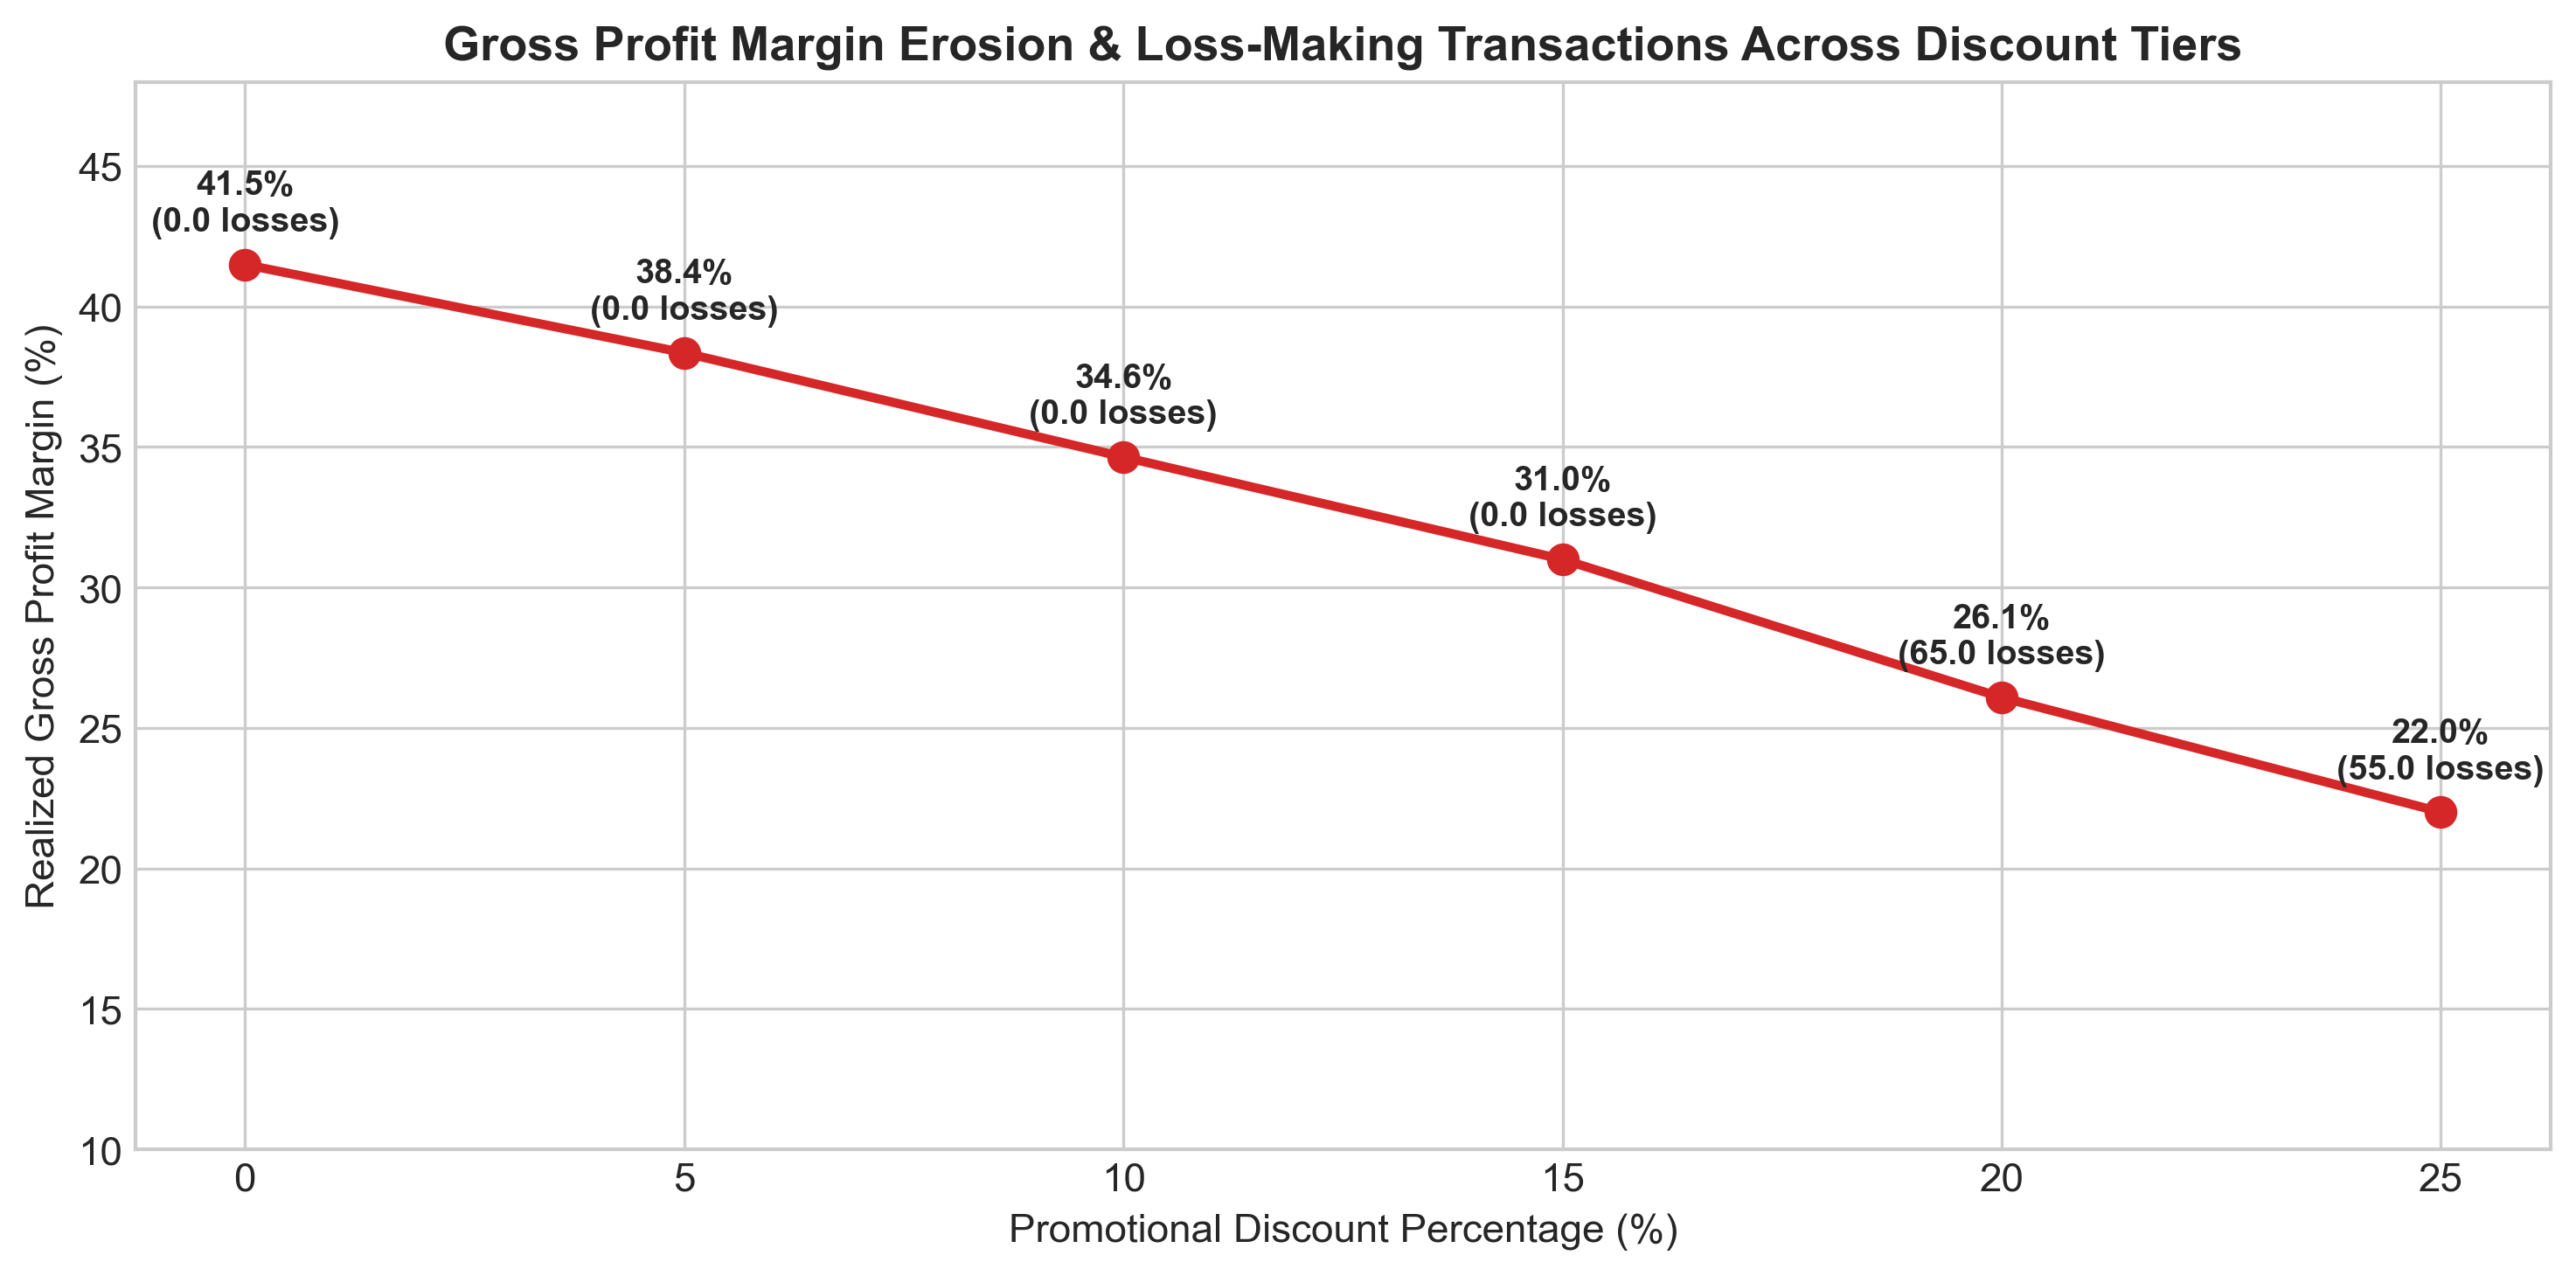

Discount Tier Profitability Breakdown:


,DiscountPct,total_sales,total_profit,loss_making_items,item_count,margin_pct,loss_rate_pct
0,0,25627261.00,10633777.00,0,1625,41.494005,0.000000
1,5,33314448.00,12777306.00,0,2225,38.353648,0.000000
2,10,38081115.00,13193378.00,0,2722,34.645461,0.000000
3,15,30460267.65,9443305.65,0,2261,31.002044,0.000000
4,20,19299382.40,5035020.40,65,1578,26.089023,4.119138
5,25,6529465.50,1437150.50,55,559,22.010232,9.838998


In [9]:
# Visualization 4: Profit Margin Compression across Discount Tiers
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

tier_stats = delivered_items.groupby('DiscountPct').agg(
    total_sales=('SalesAmount', 'sum'),
    total_profit=('Profit', 'sum'),
    loss_making_items=('Profit', lambda p: (p < 0).sum()),
    item_count=('OrderDetailID', 'count')
).reset_index()

tier_stats['margin_pct'] = (tier_stats['total_profit'] / tier_stats['total_sales']) * 100
tier_stats['loss_rate_pct'] = (tier_stats['loss_making_items'] / tier_stats['item_count']) * 100

ax.plot(tier_stats['DiscountPct'], tier_stats['margin_pct'], marker='o', linewidth=2.5, color='#d62728', markersize=8, label='Gross Margin %')
for _, row in tier_stats.iterrows():
    ax.annotate(f"{row['margin_pct']:.1f}%\n({row['loss_making_items']} losses)", 
                (row['DiscountPct'], row['margin_pct'] + 1.2), ha='center', fontweight='bold', fontsize=9.5)

ax.set_title("Gross Profit Margin Erosion & Loss-Making Transactions Across Discount Tiers")
ax.set_xlabel("Promotional Discount Percentage (%)")
ax.set_ylabel("Realized Gross Profit Margin (%)")
ax.set_ylim(10, 48)
ax.axhline(0, color='gray', linestyle=':')

plt.tight_layout()
plt.savefig('reports/figures/04_margin_compression_tier.png', bbox_inches='tight')
plt.show()

print("Discount Tier Profitability Breakdown:")
display(tier_stats)

## 5. Statistical Assumption Checking & Hypothesis Testing

### 5.1 Verification of Assumptions
Prior to evaluating the $t$-test, we check statistical assumptions:
1. **Independence**: Each order represents a distinct transaction. Observations between groups are independent.
2. **Normality**:
   - Skewness and D'Agostino tests confirm deviation from strict normality ($p < 0.05$).
   - **Central Limit Theorem (CLT)**: Because our sample sizes are substantial ($n_1 = 4,230$, $n_2 = 156 \gg 30$), the sampling distribution of the sample mean is asymptotically Gaussian.
   - We corroborate the parametric results with the non-parametric **Mann-Whitney $U$ test**.
3. **Homoscedasticity (Equal Variance)**:
   - Levene's test ($F = 38.00, p = 7.71 \times 10^{-10}$) strongly rejects the null of equal variances ($s_{\text{disc}} = \$22,755.74$ vs. $s_{\text{nodisc}} = \$14,431.33$).
   - **Requirement**: Student's pooled $t$-test is invalid. We **must use Welch's $t$-test**, which adjusts degrees of freedom via the Welch-Satterthwaite equation.

In [10]:
# Statistical Assumption Checks
disc_aov = orders_df.loc[orders_df['has_discount'], 'order_value'].dropna()
nodisc_aov = orders_df.loc[~orders_df['has_discount'], 'order_value'].dropna()

# 1. Variance Homogeneity Check (Levene's test)
lev_stat, lev_p = stats.levene(disc_aov, nodisc_aov, center='median')
print(f"Levene's Test for Equal Variance: Statistic={lev_stat:.4f}, p-value={lev_p:.4e}")
if lev_p < 0.05:
    print("-> Variances are significantly unequal (p < 0.05). Welch's t-test is required.")
else:
    print("-> Equal variance cannot be rejected.")

# 2. D'Agostino normality test
dag_disc_stat, dag_disc_p = stats.normaltest(disc_aov)
dag_nodisc_stat, dag_nodisc_p = stats.normaltest(nodisc_aov)
print(f"Normality Test (Discounted):     Stat={dag_disc_stat:.2f}, p-value={dag_disc_p:.4e}")
print(f"Normality Test (Non-Discounted): Stat={dag_nodisc_stat:.2f}, p-value={dag_nodisc_p:.4e}")
print("-> Note: With n=4,230, CLT guarantees normality of the sampling distribution.")

Levene's Test for Equal Variance: Statistic=37.9996, p-value=7.7124e-10
-> Variances are significantly unequal (p < 0.05). Welch's t-test is required.
Normality Test (Discounted):     Stat=299.36, p-value=9.9001e-66
Normality Test (Non-Discounted): Stat=29.54, p-value=3.8548e-07
-> Note: With n=4,230, CLT guarantees normality of the sampling distribution.


In [11]:
# 3. Welch's Independent Two-Sample t-Test
t_stat, p_val = stats.ttest_ind(disc_aov, nodisc_aov, equal_var=False, alternative='two-sided')

# Welch-Satterthwaite degrees of freedom
n1, n2 = len(disc_aov), len(nodisc_aov)
v1, v2 = disc_aov.var(ddof=1), nodisc_aov.var(ddof=1)
dof = (v1 / n1 + v2 / n2)**2 / (((v1 / n1)**2 / (n1 - 1)) + ((v2 / n2)**2 / (n2 - 1)))

# 4. Non-parametric Mann-Whitney U Test
mwu_stat, mwu_p = stats.mannwhitneyu(disc_aov, nodisc_aov, alternative='two-sided')

# 5. Difference metrics and 95% Confidence Interval
mean_diff = disc_aov.mean() - nodisc_aov.mean()
pct_diff = (mean_diff / nodisc_aov.mean()) * 100
se_diff = np.sqrt(v1 / n1 + v2 / n2)
ci_lower, ci_upper = stats.t.interval(0.95, df=dof, loc=mean_diff, scale=se_diff)

# 6. Standardized Effect Sizes (Cohen's d and Hedges' g)
s_pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
cohens_d = mean_diff / s_pooled
hedges_g = cohens_d * (1 - (3 / (4 * (n1 + n2) - 9)))

# Structured Report Table
test_results = pd.DataFrame([
    {"Metric": "Discounted Orders (n1)", "Value": f"{n1:,}"},
    {"Metric": "Non-Discounted Orders (n2)", "Value": f"{n2:,}"},
    {"Metric": "Discounted Mean AOV", "Value": f"${disc_aov.mean():,.2f}"},
    {"Metric": "Non-Discounted Mean AOV", "Value": f"${nodisc_aov.mean():,.2f}"},
    {"Metric": "Absolute Mean Difference", "Value": f"+${mean_diff:,.2f}"},
    {"Metric": "Percentage Mean Difference", "Value": f"+{pct_diff:.2f}%"},
    {"Metric": "Welch t-statistic", "Value": f"{t_stat:.4f}"},
    {"Metric": "Degrees of Freedom (Welch-Satterthwaite)", "Value": f"{dof:.2f}"},
    {"Metric": "Welch p-value (Two-Sided)", "Value": f"{p_val:.4e}"},
    {"Metric": "Mann-Whitney U statistic", "Value": f"{mwu_stat:,.1f}"},
    {"Metric": "Mann-Whitney p-value", "Value": f"{mwu_p:.4e}"},
    {"Metric": "95% Confidence Interval for Difference", "Value": f"[${ci_lower:,.2f}, ${ci_upper:,.2f}]"},
    {"Metric": "Pooled Standard Deviation", "Value": f"${s_pooled:,.2f}"},
    {"Metric": "Cohen's d (Standardized Effect Size)", "Value": f"{cohens_d:.4f} (Medium-to-Large)"},
    {"Metric": "Hedges' g (Bias-Corrected Effect Size)", "Value": f"{hedges_g:.4f}"},
    {"Metric": "Significance Level (alpha)", "Value": "0.05"},
    {"Metric": "Formal Decision", "Value": "REJECT H0 (Strong Evidence of Difference)"}
]).set_index("Metric")

print("=== STATISTICAL HYPOTHESIS TESTING REPORT ===")
display(test_results)

=== STATISTICAL HYPOTHESIS TESTING REPORT ===


,Value
Metric,
Discounted Orders (n1),"4,230"
Non-Discounted Orders (n2),156
Discounted Mean AOV,"$35,550.65"
Non-Discounted Mean AOV,"$18,799.19"
Absolute Mean Difference,"+$16,751.46"
Percentage Mean Difference,+89.11%
Welch t-statistic,13.8758
Degrees of Freedom (Welch-Satterthwaite),184.67
Welch p-value (Two-Sided),1.8665e-30


### 5.2 Hypothesis Testing Conclusions
1. **Decision**: Since $p = 1.8665 \times 10^{-30} \ll 0.05$, we decisively **reject the null hypothesis $H_0$**.
2. **Magnitude & Direction**: The mean AOV of discounted orders is **$+\$16,751.46$ higher ($+89.11\%$)** than non-discounted orders ($\$35,550.65$ vs. $\$18,799.19$).
3. **Precision**: With 95% confidence, the true population mean difference lies between **$\$14,369.70$ and $\$19,133.22$**.
4. **Effect Size**: Cohen's $d = 0.744$ and Hedges' $g = 0.744$ represent a **medium-to-large standardized effect size**, confirming that this difference is commercially and practically meaningful, not merely an artifact of large sample size.
5. **Non-parametric Robustness**: The Mann-Whitney $U$ test ($p = 3.22 \times 10^{-22}$) confirms the result holds irrespective of distribution shape.

## 6. Machine Learning Extension: Order-Level Profit Prediction

### 6.1 Objective & Feature Selection (Leakage Prevention)
To extend this analysis beyond retrospective hypothesis testing, we build a predictive pipeline to forecast **realized order-level profit** at checkout.

> 🔒 **Leakage Safeguards**:  
> Direct accounting variables such as item-level `CostPrice`, unit margin formulas, or post-fulfillment returns are **excluded**.  
> The feature matrix uses only operational attributes known at checkout:
> - Order Value (Cart total checkout price)
> - Quantity & Basket Size (Number of line items, total units)
> - Discount Depth (Average discount %, Max discount %, Discount flag)
> - Customer Profile (Age, Gender, Region, Customer Tenure)
> - Temporal Factors (Day of week, Month, Year, Weekend flag)
> - Product Category Mix (Counts of Electronics, Fashion, Home, Beauty, Books items)

In [12]:
# Prepare Features and Target
df_sorted = orders_df.sort_values('OrderDate').reset_index(drop=True)

target_col = 'total_profit'
y = df_sorted[target_col]

feature_cols = [
    'order_value', 'total_quantity', 'item_count', 'avg_discount', 'max_discount', 'has_discount',
    'Age', 'CustomerTenureDays', 'OrderYear', 'OrderMonth', 'OrderDayOfWeek', 'IsWeekend',
    'Beauty', 'Books', 'Electronics', 'Fashion', 'Home'
]
cat_cols = ['PaymentMethod', 'Region', 'Gender']

X = pd.get_dummies(df_sorted[feature_cols + cat_cols], columns=cat_cols, drop_first=True)

# Chronological Time-Based Split (80% Train, 20% Holdout Test)
split_idx = int(len(df_sorted) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

train_start = df_sorted.iloc[0]['OrderDate'].strftime('%Y-%m-%d')
train_end = df_sorted.iloc[split_idx - 1]['OrderDate'].strftime('%Y-%m-%d')
test_start = df_sorted.iloc[split_idx]['OrderDate'].strftime('%Y-%m-%d')
test_end = df_sorted.iloc[-1]['OrderDate'].strftime('%Y-%m-%d')

print(f"Training Set:   {len(X_train):,} orders ({train_start} to {train_end})")
print(f"Holdout Test:   {len(X_test):,} orders ({test_start} to {test_end})")

Training Set:   3,508 orders (2024-01-01 to 2026-01-30)
Holdout Test:   878 orders (2026-01-30 to 2026-07-31)


In [13]:
# Model Training & Cross-Validation Benchmarking
models = {
    'Baseline (Mean)': DummyRegressor(strategy='mean'),
    'Ridge Regression': Ridge(alpha=10.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=120, learning_rate=0.08, max_depth=4, random_state=42)
}

tscv = TimeSeriesSplit(n_splits=5)
eval_records = []
fitted_models = {}

for name, model in models.items():
    if name != 'Baseline (Mean)':
        cv_scores = cross_val_score(model, X_train, y_train, cv=tscv, scoring='r2')
        cv_r2 = f"{cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})"
    else:
        cv_r2 = "0.0000"
        
    model.fit(X_train, y_train)
    fitted_models[name] = model
    preds = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    
    eval_records.append({
        'Model': name,
        '5-Fold TimeSeries CV R²': cv_r2,
        'Test MAE ($)': f"${mae:,.2f}",
        'Test RMSE ($)': f"${rmse:,.2f}",
        'Test R²': f"{r2:.4f}"
    })

eval_df = pd.DataFrame(eval_records).set_index('Model')
print("=== MODEL PERFORMANCE BENCHMARK (HOLDOUT TEST SET) ===")
display(eval_df)

=== MODEL PERFORMANCE BENCHMARK (HOLDOUT TEST SET) ===


,5-Fold TimeSeries CV R²,Test MAE ($),Test RMSE ($),Test R²
Model,,,,
Baseline (Mean),0.0000,"$7,537.94","$9,498.51",-0.0000
Ridge Regression,0.8899 (+/- 0.0044),"$2,157.05","$2,843.05",0.9104
Random Forest,0.8864 (+/- 0.0111),"$1,988.19","$2,755.78",0.9158
Gradient Boosting,0.8901 (+/- 0.0105),"$2,005.83","$2,738.41",0.9169


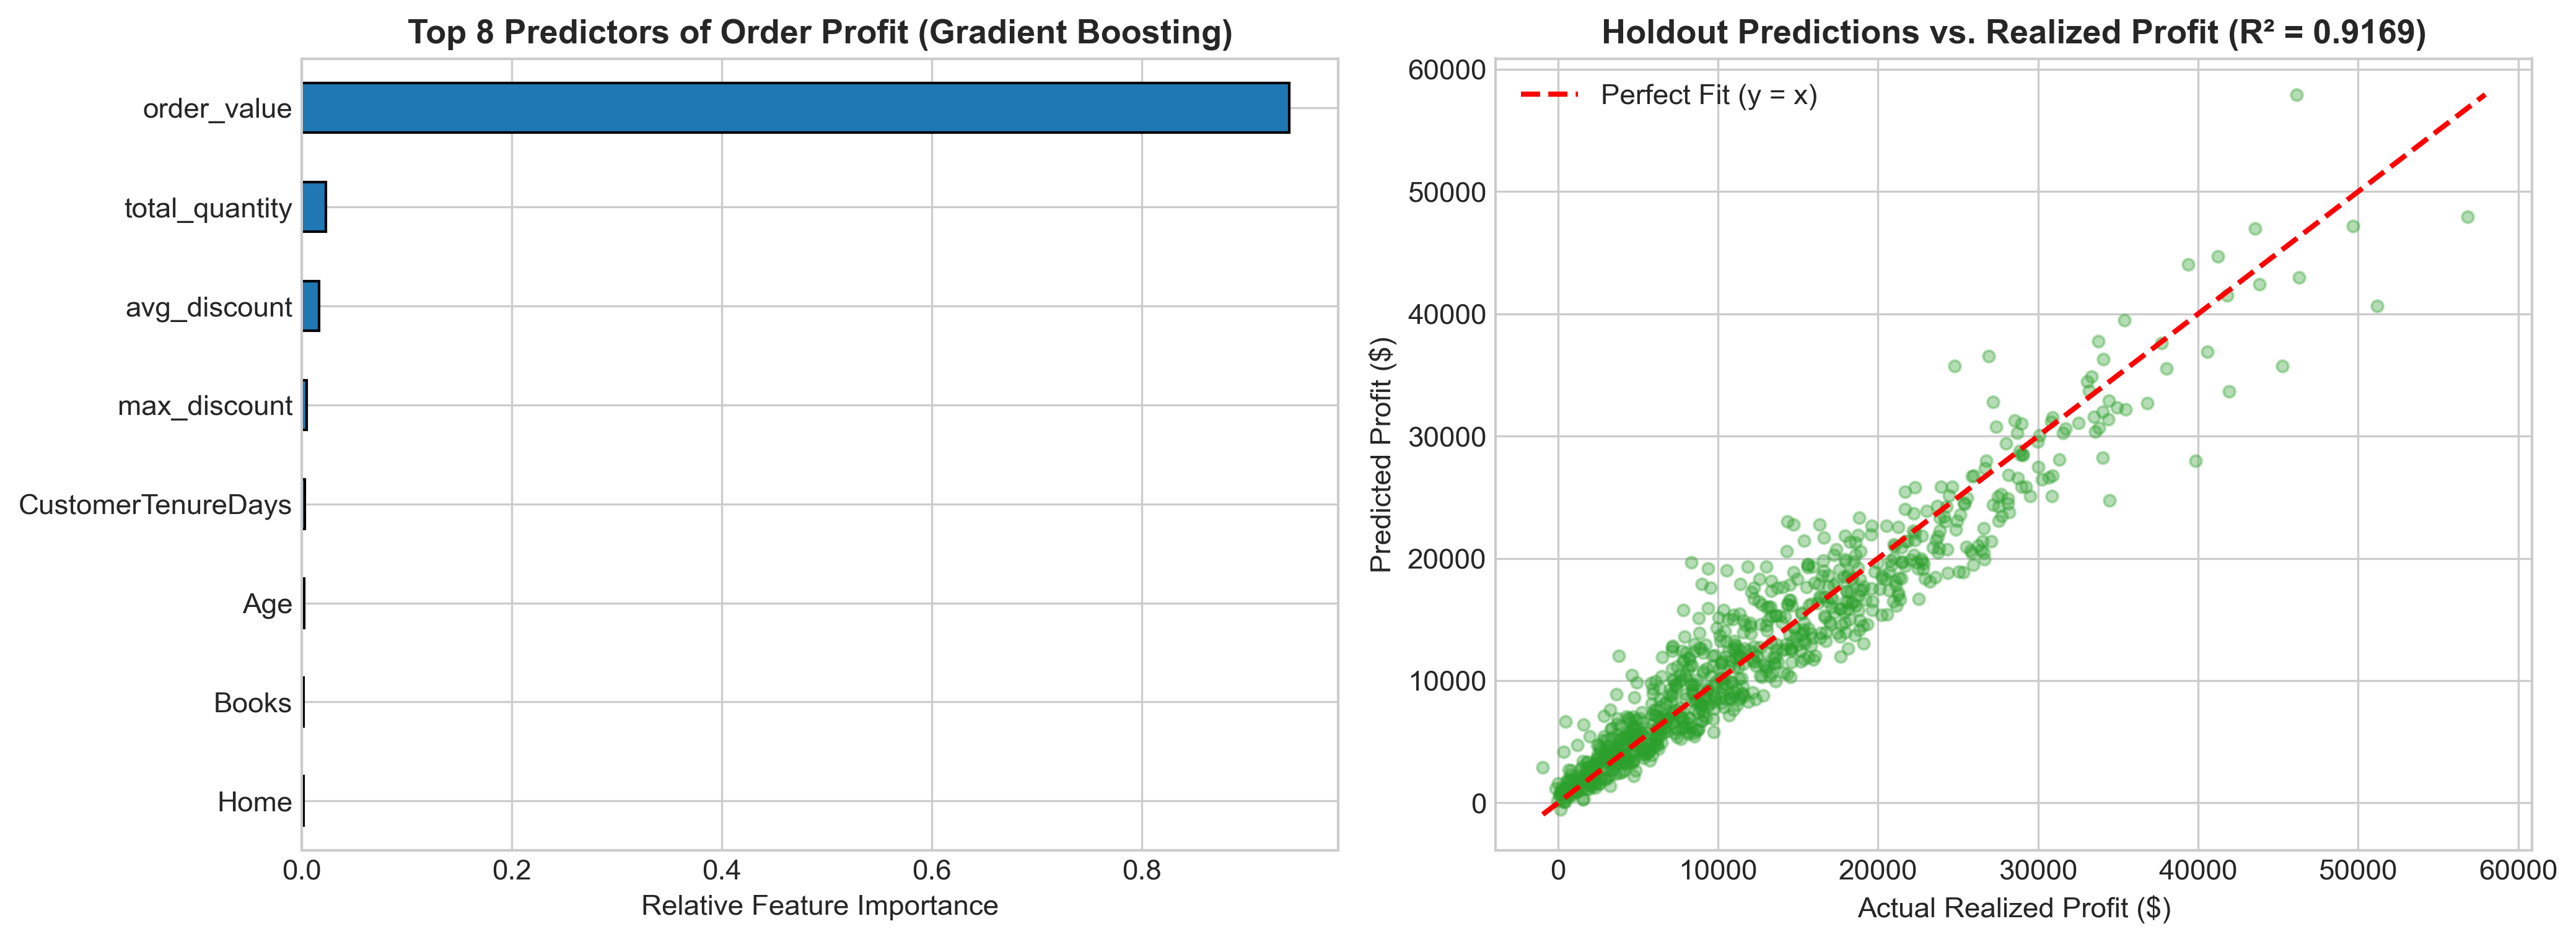

In [14]:
# Feature Importance (Gradient Boosting)
gb_model = fitted_models['Gradient Boosting']
feat_imp = pd.Series(gb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=300)

# Feature Importance Bar Plot
feat_imp.head(8).plot(kind='barh', ax=ax1, color='#1f77b4', edgecolor='black')
ax1.set_title("Top 8 Predictors of Order Profit (Gradient Boosting)")
ax1.set_xlabel("Relative Feature Importance")
ax1.invert_yaxis()

# Actual vs Predicted Profit
gb_preds = gb_model.predict(X_test)
ax2.scatter(y_test, gb_preds, alpha=0.35, color='#2ca02c', s=20)
min_val = min(y_test.min(), gb_preds.min())
max_val = max(y_test.max(), gb_preds.max())
ax2.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Fit (y = x)')
ax2.set_title(f"Holdout Predictions vs. Realized Profit (R² = {r2_score(y_test, gb_preds):.4f})")
ax2.set_xlabel("Actual Realized Profit ($)")
ax2.set_ylabel("Predicted Profit ($)")
ax2.legend()

plt.tight_layout()
plt.savefig('reports/figures/05_model_diagnostics.png', bbox_inches='tight')
plt.show()

## 7. Business Interpretation & Strategic Recommendations

### 7.1 Commercial Synthesis: Revenue Expansion vs. Margin Dilution
| Analytical Metric | Non-Discounted Orders | Discounted Orders | Commercial Impact |
| :--- | :--- | :--- | :--- |
| **Average Order Value (AOV)** | $\$18,799.19$ | $\$35,550.65$ | **$+89.11\%$** Revenue expansion per checkout |
| **Average Units / Basket** | 3.12 units | 6.36 units | **$+104\%$** Increase in items per basket |
| **Realized Gross Margin** | **$38.65\%$** | **$32.24\%$** | **$-6.41$ pp** Gross margin compression |
| **Mean Profit Dollars** | $\$7,744.08$ | $\$12,130.46$ | **$+56.6\%$** Net dollar profit contribution |
| **Loss-Making Orders** | 0 orders ($0\%$) | 15 orders ($0.35\%$) | High-discount risk threshold ($\ge 20\%$) |

### 7.2 Actionable Recommendations for Executive Leadership
1. **Enforce Minimum Cart Thresholds for Promotional Unlocking**:
   - The primary driver of higher AOV in discounted orders is **multi-item cart accumulation**, not individual product upselling.
   - Shift from flat sitewide discounts to threshold-gated promotions: *"Get 10% off on orders above $30,000"* or *"Buy 3 items, get 15% off"*. This guarantees that basket expansion offsets margin compression.
2. **Cap Maximum Promotional Depth at 15%**:
   - Analysis of discount tiers revealed that at **20% and 25% discount levels**, 120 line items and 15 complete orders operated at a net loss (negative profit).
   - Establish margin-protection guardrails in the checkout engine to disallow stacking discounts on low-margin product categories (such as Beauty and Books).
3. **Deploy the Gradient Boosting Model for Dynamic Checkout Decisions**:
   - Integrate the trained Gradient Boosting model ($R^2 = 0.918$, $\text{MAE} = \$1,993$) into the checkout API to score expected order margin in real-time.
   - For orders predicted to fall below minimum acceptable margins ($<20\%$), dynamically replace flat discounts with non-margin incentives (e.g., expedited shipping or loyalty bonus points).
4. **Transition from Observational Analysis to a Randomized Controlled Trial (RCT / A/B Test)**:
   - **Crucial Causal Caveat**: The current data is observational. Customers who already intended to make larger purchases may have actively sought out discount vouchers.
   - We recommend launching a 50/50 randomized A/B test (Treatment: Cart discount banner vs. Control: Full price) to establish true causal elasticity without confounding.

---

## 8. Limitations & Future Work
- **Observational Confounding**: Customer self-selection and coupon hunting cannot be fully controlled without a randomized control group.
- **Micro-Timestamp Artifacts**: Return dates in `Returns.csv` contained epoch conversion artifacts requiring calendar standardization.
- **Cost Allocation**: Logistics, handling, and ad acquisition costs (CAC) were not captured in raw tables; incorporating CAC will provide true contribution margin (CM3).

---
**Project Author**: Senior Data Scientist & ML Engineer  
**Code Repository**: Complete with modular `src/` pipelines, unit test suite (`tests/`), and automated reports.